# Task 2 — Notebook 4: Exploratory Data Analysis

This notebook explores the **training split only**. The validation and test sets are not used here, so their later observations remain untouched until model evaluation.

The purpose of this EDA is to understand data quality, class imbalance, distributions, and simple relationships that can guide feature engineering.

**Input:** `artifacts/tables/03_train.parquet`

**Outputs:** charts under `artifacts/charts/` and a short report at `artifacts/reports/04_findings.md`


## 1. Imports and paths


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

import sys

src_dir = Path.cwd().resolve()
while src_dir != src_dir.parent and not (src_dir / "Task2").is_dir():
    src_dir = src_dir.parent
src_dir = src_dir / "Task2" / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from config import find_project_root

PROJECT_ROOT = find_project_root()
TASK2_ROOT = PROJECT_ROOT / "Task2"
ARTIFACTS_DIR = TASK2_ROOT / "artifacts"
TABLES_DIR = ARTIFACTS_DIR / "tables"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
CHARTS_DIR = ARTIFACTS_DIR / "charts"

for folder in [REPORTS_DIR, CHARTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

input_path = TABLES_DIR / "03_train.parquet"
if not input_path.exists():
    raise FileNotFoundError(f"Training artifact not found: {input_path}")


## 2. Load the training data

The target column is `is_late`. Columns that describe events after delivery, such as the actual delivery timestamp, must not be used as predictive features later because they would leak the answer.


In [2]:
train = pd.read_parquet(input_path)

train["order_purchase_timestamp"] = pd.to_datetime(
    train["order_purchase_timestamp"], errors="coerce"
)

assert "is_late" in train.columns
assert train["order_id"].is_unique

print(f"Rows: {len(train):,}")
print(f"Columns: {len(train.columns)}")
print(f"Late-delivery rate: {train['is_late'].mean() * 100:.2f}%")
display(train.head())


Rows: 67,529
Columns: 27
Late-delivery rate: 9.03%


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,num_product_categories,avg_product_weight_g,avg_product_photos_qty,seller_state_count,payment_record_count,total_payment_value,max_payment_installments,review_record_count,avg_review_score,is_late
0,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,830d5b7aaa3b6f1e9ad63703bec97d23,14600,...,1.0,1000.0,1.0,1.0,NaN,NaN,NaN,1.0,1.0,1
1,3b697a20d9e427646d92567910af6d57,355077684019f7f60a031656bd7262b8,delivered,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27,32ea3bdedab835c3aa6cb68ce66565ef,4106,...,1.0,300.0,3.0,1.0,1.0,45.46,1.0,1.0,4.0,0
2,be5bc2f0da14d8071e2d45451ad119d9,7ec40b22510fdbea1b08921dd39e63d8,delivered,2016-10-03 16:56:50,2016-10-06 16:03:44,2016-10-21 16:33:46,2016-10-27 18:19:38,2016-11-07,2f64e403852e6893ae37485d5fcacdaf,98280,...,1.0,400.0,1.0,1.0,1.0,39.09,1.0,1.0,4.0,0
3,a41c8759fbe7aab36ea07e038b2d4465,6f989332712d3222b6571b1cf5b835ce,delivered,2016-10-03 21:13:36,2016-10-05 03:11:49,2016-10-25 11:57:59,2016-11-03 10:58:07,2016-11-29,61db744d2f835035a5625b59350c6b63,90040,...,1.0,767.0,1.0,1.0,1.0,53.73,1.0,1.0,3.0,0
4,d207cc272675637bfed0062edffd0818,b8cf418e97ae795672d326288dfab7a7,delivered,2016-10-03 22:06:03,2016-10-04 10:28:07,2016-10-21 14:23:37,2016-10-31 11:07:42,2016-11-23,8d3a54507421dbd2ce0a1d58046826e0,13185,...,1.0,2050.0,1.0,1.0,1.0,133.46,6.0,1.0,1.0,0


## 3. Data quality overview


In [3]:
quality = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "missing_count": train.isna().sum(),
    "missing_percentage": (train.isna().mean() * 100).round(2),
    "unique_values": train.nunique(dropna=True),
}).sort_values("missing_percentage", ascending=False)

display(quality)
print(f"Duplicate rows: {train.duplicated().sum():,}")


,dtype,missing_count,missing_percentage,unique_values
avg_product_photos_qty,float64,1197,1.77,58
review_record_count,float64,515,0.76,3
avg_review_score,float64,515,0.76,11
avg_product_weight_g,float64,16,0.02,2272
order_approved_at,datetime64[ns],14,0.02,63147
order_delivered_carrier_date,datetime64[ns],1,0.00,63238
order_delivered_customer_date,datetime64[ns],0,0.00,66954
order_status,object,0,0.00,1
order_purchase_timestamp,datetime64[ns],0,0.00,67151
customer_id,object,0,0.00,67529


Duplicate rows: 0


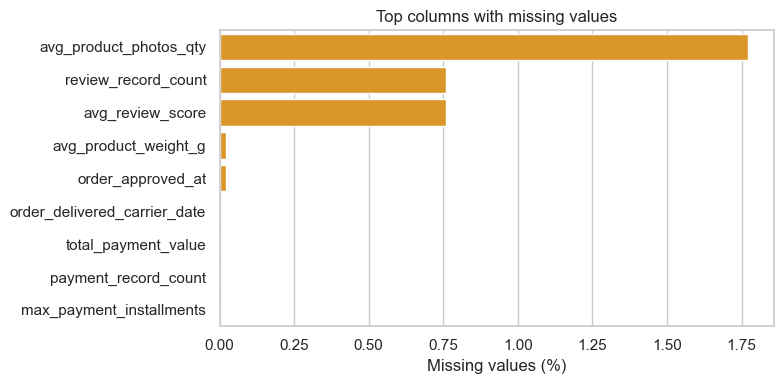

In [4]:
missing = quality[quality["missing_count"] > 0].head(10)

if len(missing) > 0:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(
        data=missing.reset_index(names="column"),
        x="missing_percentage",
        y="column",
        color="#f59e0b",
        ax=ax,
    )
    ax.set_title("Top columns with missing values")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()
    fig.savefig(CHARTS_DIR / "04_missing_values.png", dpi=150, bbox_inches="tight")
else:
    print("No missing values were found.")


## 4. Target distribution

The late-delivery class is expected to be smaller than the on-time class. This imbalance must be considered during model training and evaluation.


,label,count,percentage
0,on_time,61433,90.97
1,late,6096,9.03


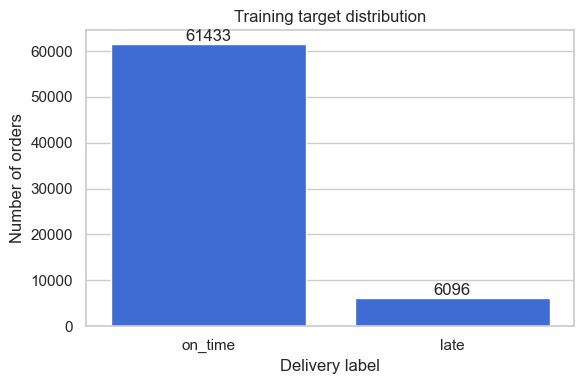

In [5]:
target_counts = train["is_late"].value_counts().sort_index()
target_table = pd.DataFrame({
    "label": ["on_time", "late"],
    "count": [target_counts.get(0, 0), target_counts.get(1, 0)],
})
target_table["percentage"] = (target_table["count"] / len(train) * 100).round(2)
display(target_table)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=target_table, x="label", y="count", color="#2563eb", ax=ax)
ax.set_title("Training target distribution")
ax.set_xlabel("Delivery label")
ax.set_ylabel("Number of orders")
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.tight_layout()
plt.show()
fig.savefig(CHARTS_DIR / "04_target_distribution.png", dpi=150, bbox_inches="tight")


## 5. Numerical feature distributions

The selected variables describe the order before delivery: price, freight, item counts, payment information, and product information. Skewed variables may need transformations or robust scaling in a later notebook.


In [6]:
candidate_numeric = [
    "total_price", "total_freight", "total_payment_value",
    "num_items", "num_distinct_products", "num_sellers",
    "num_product_categories", "avg_product_weight_g",
    "avg_product_photos_qty", "max_payment_installments",
    "avg_review_score",
]
numeric_columns = [column for column in candidate_numeric if column in train.columns]

numeric_summary = train[numeric_columns].describe().T
numeric_summary["missing"] = train[numeric_columns].isna().sum()
display(numeric_summary)


,count,mean,std,min,25%,50%,75%,max,missing
total_price,67529.0,135.888797,205.194019,2.29,45.90,85.00,149.9,13440.00,0
total_freight,67529.0,22.245936,20.002594,0.00,14.10,16.79,23.7,1002.29,0
total_payment_value,67528.0,158.173637,214.285757,10.07,61.63,104.19,175.5,13664.08,1
num_items,67529.0,1.142072,0.541640,1.00,1.00,1.00,1.0,21.00,0
num_distinct_products,67529.0,1.037702,0.222199,1.00,1.00,1.00,1.0,7.00,0
num_sellers,67529.0,1.012054,0.114815,1.00,1.00,1.00,1.0,5.00,0
num_product_categories,67529.0,0.988953,0.156398,0.00,1.00,1.00,1.0,3.00,0
avg_product_weight_g,67513.0,2171.789992,3866.698263,2.00,300.00,700.00,1850.0,40425.00,16
avg_product_photos_qty,66332.0,2.245279,1.743277,1.00,1.00,2.00,3.0,20.00,1197
max_payment_installments,67528.0,2.974559,2.755168,1.00,1.00,2.00,4.0,24.00,1


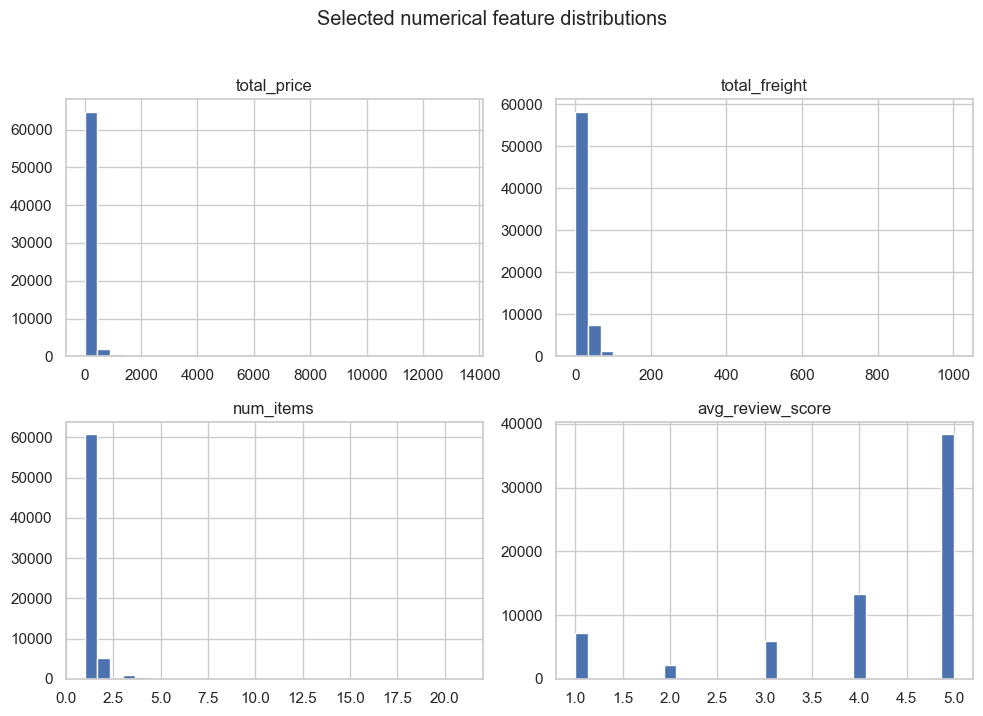

<Figure size 640x480 with 0 Axes>

In [7]:
plot_columns = [
    column for column in ["total_price", "total_freight", "num_items", "avg_review_score"]
    if column in train.columns
]

if plot_columns:
    train[plot_columns].hist(figsize=(10, 7), bins=30, edgecolor="white")
    plt.suptitle("Selected numerical feature distributions", y=1.02)
    plt.tight_layout()
    plt.show()
    plt.savefig(CHARTS_DIR / "04_numeric_distributions.png", dpi=150, bbox_inches="tight")


## 6. Late-delivery rate by customer state

This is a simple group comparison, not a causal conclusion. It can show whether geographic information may be useful for a later model.


,customer_state,orders,late_rate,late_rate_percentage
1,AL,298,0.278523,27.85
9,MA,548,0.215328,21.53
5,CE,948,0.182489,18.25
21,RR,29,0.172414,17.24
24,SE,246,0.170732,17.07
16,PI,348,0.166667,16.67
18,RJ,8965,0.165867,16.59
4,BA,2307,0.149978,15.00
13,PA,718,0.133705,13.37
7,ES,1445,0.132872,13.29


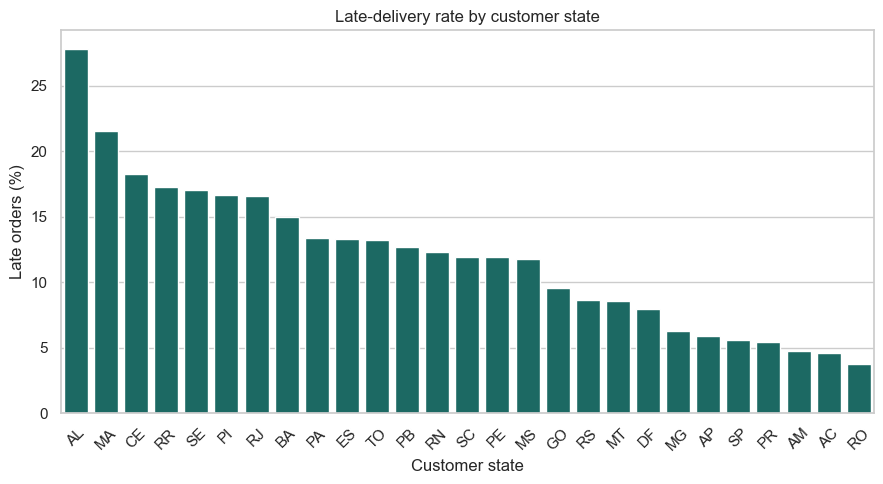

In [8]:
if "customer_state" in train.columns:
    state_summary = (
        train.groupby("customer_state", as_index=False)
        .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"))
    )
    state_summary["late_rate_percentage"] = (state_summary["late_rate"] * 100).round(2)
    state_summary = state_summary.sort_values("late_rate", ascending=False)
    display(state_summary.head(10))

    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(
        data=state_summary,
        x="customer_state",
        y="late_rate_percentage",
        color="#0f766e",
        ax=ax,
    )
    ax.set_title("Late-delivery rate by customer state")
    ax.set_xlabel("Customer state")
    ax.set_ylabel("Late orders (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    fig.savefig(CHARTS_DIR / "04_late_rate_by_state.png", dpi=150, bbox_inches="tight")


## 7. Late-delivery rate over time

The monthly view helps identify changes in delivery performance across the purchase period.


,purchase_month,orders,late_rate,late_rate_percentage
0,2016-09,1,1.000000,100.00
1,2016-10,265,0.011321,1.13
2,2016-12,1,0.000000,0.00
3,2017-01,750,0.030667,3.07
4,2017-02,1653,0.032063,3.21
5,2017-03,2546,0.055774,5.58
6,2017-04,2303,0.078593,7.86
7,2017-05,3545,0.036107,3.61
8,2017-06,3135,0.038596,3.86
9,2017-07,3872,0.034349,3.43


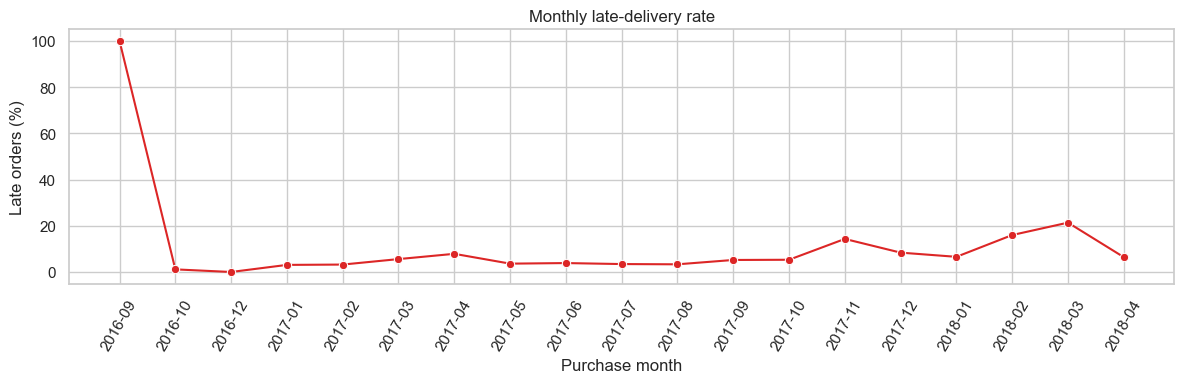

In [9]:
train["purchase_month"] = train["order_purchase_timestamp"].dt.to_period("M").astype(str)
monthly_summary = (
    train.groupby("purchase_month", as_index=False)
    .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"))
)
monthly_summary["late_rate_percentage"] = (monthly_summary["late_rate"] * 100).round(2)
display(monthly_summary)

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(
    data=monthly_summary,
    x="purchase_month",
    y="late_rate_percentage",
    marker="o",
    color="#dc2626",
    ax=ax,
)
ax.set_title("Monthly late-delivery rate")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Late orders (%)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()
fig.savefig(CHARTS_DIR / "04_monthly_late_rate.png", dpi=150, bbox_inches="tight")


## 8. Record findings for the next notebook


In [10]:
leakage_columns = [
    column for column in [
        "order_delivered_customer_date",
        "order_delivered_carrier_date",
        "delivery_days",
    ]
    if column in train.columns
]

findings = f'''# Task 2 — Notebook 4 EDA Findings

## Dataset

- Training rows: {len(train):,}
- Columns: {len(train.columns):,}
- Late-delivery rate: {train['is_late'].mean() * 100:.2f}%
- Duplicate rows: {int(train.duplicated().sum()):,}

## Data quality

The table above reports data types, missing counts, missing percentages, and unique-value counts. Missing values should be handled inside the modeling pipeline rather than filled using information from validation or test data.

## Modeling considerations

- The target is imbalanced, so accuracy alone is not sufficient for evaluation.
- Price, freight, payment, item-count, product, and geographic variables are candidates for feature engineering.
- Skewed numeric variables may benefit from robust preprocessing or transformations.
- The following post-delivery columns must be excluded from predictive features to avoid leakage: {', '.join(leakage_columns) if leakage_columns else 'none found in this table'}.
- This EDA used the training split only.
'''

report_path = REPORTS_DIR / "04_findings.md"
report_path.write_text(findings, encoding="utf-8")
print(f"Saved EDA findings to: {report_path}")


Saved EDA findings to: C:\Users\HP\Desktop\MLOps\Task2\artifacts\reports\04_findings.md


## 9. Final checks


In [11]:
assert len(train) > 0
assert train["is_late"].isin([0, 1]).all()
assert (REPORTS_DIR / "04_findings.md").exists()
assert (CHARTS_DIR / "04_target_distribution.png").exists()
print("ALL NOTEBOOK 4 CHECKS PASSED")


ALL NOTEBOOK 4 CHECKS PASSED
